# FDSAI Lab – Hypothesis Testing

**Contents**
1. Setup and data loading
2. Exercise 1a – evaluation score vs. gender
3. Exercise 1c – minority status vs. probation (tenure)
4. Exercise 2 – jump height before / after training

Significance level used everywhere: **α = 0.05**.

## 1. Setup and data loading

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy import stats

sns.set_theme(style="whitegrid")
ALPHA = 0.05

# The original IBM link is no longer reachable; this is the same dataset (AER::TeachingRatings)
URL = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/AER/TeachingRatings.csv"
df = pd.read_csv(URL).drop(columns="rownames")
print(df.shape)
df.head()

(463, 12)


,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


In [25]:
df.info()
print()
print(df[["minority", "gender", "tenure"]].apply(lambda s: s.value_counts().to_dict()))
df[["eval", "beauty", "age"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   minority     463 non-null    object 
 1   age          463 non-null    int64  
 2   gender       463 non-null    object 
 3   credits      463 non-null    object 
 4   beauty       463 non-null    float64
 5   eval         463 non-null    float64
 6   division     463 non-null    object 
 7   native       463 non-null    object 
 8   tenure       463 non-null    object 
 9   students     463 non-null    int64  
 10  allstudents  463 non-null    int64  
 11  prof         463 non-null    int64  
dtypes: float64(2), int64(4), object(6)
memory usage: 43.5+ KB

minority          {'no': 399, 'yes': 64}
gender      {'male': 268, 'female': 195}
tenure           {'yes': 361, 'no': 102}
dtype: object


,eval,beauty,age
count,463.000000,4.630000e+02,463.000000
mean,3.998272,6.263499e-08,48.365011
std,0.554866,7.886477e-01,9.802742
min,2.100000,-1.450494e+00,29.000000
25%,3.600000,-6.562689e-01,42.000000
50%,4.000000,-6.801430e-02,48.000000
75%,4.400000,5.456024e-01,57.000000
max,5.000000,1.970023e+00,73.000000


Relevant variables:
- `eval` – average course evaluation score (the grade obtained in the evaluation)
- `gender` – instructor's gender (`male` / `female`)
- `beauty` – beauty score (standardized)
- `age` – instructor's age
- `minority` – belongs to a minority group (`yes` / `no`)
- `tenure` – has a permanent position (`yes`) or not (`no`). **"On probation" = `tenure == 'no'`**.

In [26]:
def interpret(p, h0, h1, alpha=ALPHA):
    print("-" * 70)
    if p < alpha:
        print(f"p = {p:.4g} < {alpha}  ->  REJECT H0.")
        print(f"Conclusion: there is sufficient statistical evidence for H1 ({h1}).")
    else:
        print(f"p = {p:.4g} >= {alpha}  ->  FAIL TO REJECT H0.")
        print(f"Conclusion: there is not enough evidence for H1; the data are compatible with H0 ({h0}).")
    print("-" * 70)


def normality_ok(groups, alpha=ALPHA):
    """groups: dict name -> array. Prints Shapiro-Wilk results and returns True if all groups
    are considered approximately normal (Shapiro p > alpha, or n >= 30 by the CLT)."""
    ok = True
    for name, x in groups.items():
        p = stats.shapiro(x).pvalue if len(x) >= 3 else np.nan
        passed = (p > alpha) or (len(x) >= 30)
        ok &= passed
        reason = "normal" if p > alpha else ("n>=30 (CLT)" if len(x) >= 30 else "NOT normal")
        print(f"  Shapiro [{name}]: n={len(x)}, p={p:.4g} -> {reason}")
    return ok


def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * np.var(a, ddof=1) + (nb - 1) * np.var(b, ddof=1)) / (na + nb - 2))
    return (np.mean(a) - np.mean(b)) / sp

##Exercise 1a – Evaluation score (`eval`) by gender

**H0:** the mean evaluation score is the same for men and women (μ_male = μ_female).  
**H1:** the means differ (μ_male ≠ μ_female) – **two-sided** test.

**Conditions for the independent-samples t-test:**
1. Independent observations and two independent groups.
2. Normality of the score within each group (or large n → CLT).
3. Homogeneity of variances (if violated: Welch's t-test).

If normality is not satisfied → **Mann-Whitney U**.

        count   mean    std  median
gender                             
female    195  3.901  0.539    3.90
male      268  4.069  0.557    4.15


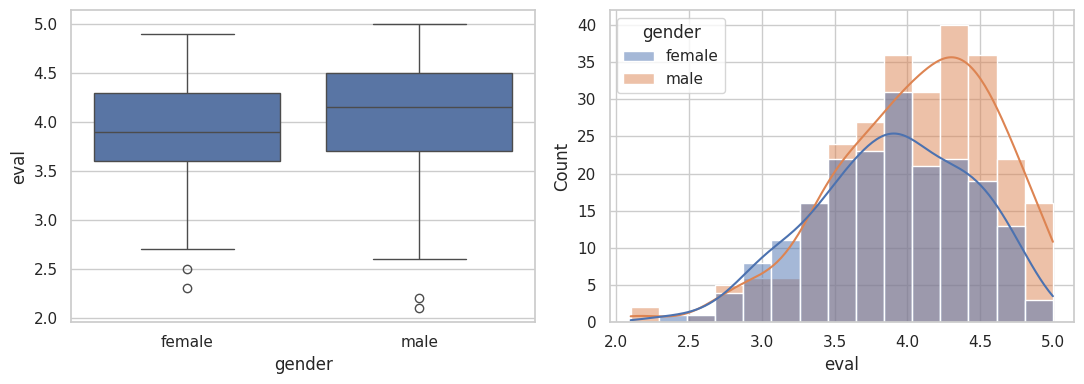


--- Checking the conditions ---
  Shapiro [male]: n=268, p=1.388e-05 -> n>=30 (CLT)
  Shapiro [female]: n=195, p=0.01173 -> n>=30 (CLT)
  Levene: p=0.7298 -> variances equal

--- The test ---
Independent t-test (Student): t=3.250, p=0.001239
Cohen's d = 0.306
(Check) Mann-Whitney U: p=0.0007568
----------------------------------------------------------------------
p = 0.001239 < 0.05  ->  REJECT H0.
Conclusion: there is sufficient statistical evidence for H1 (the mean evaluation score differs between genders).
----------------------------------------------------------------------


In [27]:
male = df.loc[df["gender"] == "male", "eval"].values
female = df.loc[df["gender"] == "female", "eval"].values

print(df.groupby("gender")["eval"].agg(["count", "mean", "std", "median"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="gender", y="eval", ax=ax[0])
sns.histplot(data=df, x="eval", hue="gender", kde=True, ax=ax[1])
plt.tight_layout(); plt.show()

print("\n--- Checking the conditions ---")
norm = normality_ok({"male": male, "female": female})
lev = stats.levene(male, female)
print(f"  Levene: p={lev.pvalue:.4g} -> variances {'equal' if lev.pvalue > ALPHA else 'DIFFERENT'}")

H0 = "the mean evaluation score is equal for the two genders"
H1 = "the mean evaluation score differs between genders"
print("\n--- The test ---")
if norm:
    equal_var = lev.pvalue > ALPHA
    res = stats.ttest_ind(male, female, equal_var=equal_var)
    print(f"Independent t-test ({'Student' if equal_var else 'Welch'}): t={res.statistic:.3f}, p={res.pvalue:.4g}")
    print(f"Cohen's d = {cohens_d(male, female):.3f}")
    p_1a = res.pvalue
else:
    res = stats.mannwhitneyu(male, female, alternative="two-sided")
    print(f"Mann-Whitney U: U={res.statistic:.1f}, p={res.pvalue:.4g}")
    p_1a = res.pvalue

# robustness check with the non-parametric test
mw = stats.mannwhitneyu(male, female, alternative="two-sided")
print(f"(Check) Mann-Whitney U: p={mw.pvalue:.4g}")
interpret(p_1a, H0, H1)

## Exercise 1b – Beauty score by age categories

**Question:** Does the beauty score differ depending on age?

We perform this analysis in two ways:
1. Dividing ages into **3 categories**: under 40 years, 40–57 years, and over 57 years.
2. Dividing ages into **6 subgroups** (equal-width intervals).

### Hypotheses Formulation
* **Null Hypothesis ($H_0$):** The mean beauty score is the same in all age groups.
* **Alternative Hypothesis ($H_1$):** At least one age group has a different mean beauty score.

### Conditions for ANOVA:
- Normality of the distribution within each group.
- Homogeneity of variances (Levene's test).
- If these conditions are violated, we will use the non-parametric **Kruskal-Wallis** test.

In [28]:
def evaluate_age_groups(data, group_col):
    print(f"\n--- Analysis for {group_col} ---")
    # Explicitly set observed=False to avoid FutureWarnings
    grouped = {str(k): g["beauty"].values for k, g in data.groupby(group_col, observed=False) if len(g) > 0}

    # Descriptive statistics
    desc = data.groupby(group_col, observed=False)["beauty"].agg(["count", "mean", "std"]).round(3)
    display(desc)

    # Test conditions
    norm_passed = True
    for name, values in grouped.items():
        if len(values) >= 3:
            sh_p = stats.shapiro(values).pvalue
            if sh_p <= ALPHA and len(values) < 30:
                norm_passed = False

    lev_p = stats.levene(*grouped.values()).pvalue
    print(f"Levene's test for homogeneity of variances: p-value = {lev_p:.4g}")

    if norm_passed and lev_p > ALPHA:
        res = stats.f_oneway(*grouped.values())
        print(f"Applying ANOVA: F = {res.statistic:.3f}, p-value = {res.pvalue:.4g}")
        p_val = res.pvalue
    else:
        res = stats.kruskal(*grouped.values())
        print(f"ANOVA conditions not met. Applying Kruskal-Wallis: H = {res.statistic:.3f}, p-value = {res.pvalue:.4g}")
        p_val = res.pvalue

    interpret(p_val, "beauty score is equal across all groups", "beauty score differs across groups")
    return p_val

# 1. Divide into 3 categories
df["age_3"] = pd.cut(df["age"], bins=[0, 39, 57, 200], labels=["under 40", "40-57", "over 57"])
p_3 = evaluate_age_groups(df, "age_3")

# 2. Divide into 6 subgroups (equal-width)
df["age_6"] = pd.cut(df["age"], bins=6, precision=0)
p_6 = evaluate_age_groups(df, "age_6")


--- Analysis for age_3 ---


,count,mean,std
age_3,,,
under 40,105,0.413,0.902
40-57,264,-0.081,0.673
over 57,94,-0.235,0.795


Levene's test for homogeneity of variances: p-value = 0.001423
ANOVA conditions not met. Applying Kruskal-Wallis: H = 39.647, p-value = 2.459e-09
----------------------------------------------------------------------
p = 2.459e-09 < 0.05  ->  REJECT H0.
Conclusion: there is sufficient statistical evidence for H1 (beauty score differs across groups).
----------------------------------------------------------------------

--- Analysis for age_6 ---


,count,mean,std
age_6,,,
"(29.0, 36.0]",68,0.443,0.897
"(36.0, 44.0]",93,0.065,0.789
"(44.0, 51.0]",117,0.004,0.656
"(51.0, 58.0]",105,-0.018,0.844
"(58.0, 66.0]",72,-0.403,0.562
"(66.0, 73.0]",8,-0.725,0.008


Levene's test for homogeneity of variances: p-value = 2.452e-06
ANOVA conditions not met. Applying Kruskal-Wallis: H = 48.813, p-value = 2.424e-09
----------------------------------------------------------------------
p = 2.424e-09 < 0.05  ->  REJECT H0.
Conclusion: there is sufficient statistical evidence for H1 (beauty score differs across groups).
----------------------------------------------------------------------


## Exercise 1c – Minority status and probation

**Definition:** Probation is defined by the condition `tenure == 'no'` (the instructor does not yet have a permanent position).

### Hypotheses Formulation
* **Null Hypothesis ($H_0$):** Belonging to a minority group and probation status are **independent**.
* **Alternative Hypothesis ($H_1$):** There is a significant **association** between belonging to a minority group and probation status.

### Conditions for the $\chi^2$ Test of Independence:
- Independent observations.
- Expected frequencies $\ge 5$ in all cells of the contingency table. If this condition is not met, **Fisher's Exact Test** will be used instead.

In [29]:
df["probation"] = np.where(df["tenure"] == "no", "yes", "no")
obs = pd.crosstab(df["minority"], df["probation"])

print("Observed frequencies:")
display(obs)

# Compute expected frequencies under H0
chi2, p, dof, expected = stats.chi2_contingency(obs, correction=False)
exp_df = pd.DataFrame(expected, index=obs.index, columns=obs.columns)
print("\nExpected frequencies:")
display(exp_df.round(2))

cond = (expected >= 5).all()
print(f"All expected frequencies >= 5: {cond}")

H0_1c = "minority status and probation are independent"
H1_1c = "there is an association between minority status and probation"

if cond:
    # Using Yates' correction for 2x2 contingency table
    chi2c, pc, _, _ = stats.chi2_contingency(obs, correction=True)
    print(f"\nChi-Square test (with Yates' correction): chi2 = {chi2c:.3f}, p-value = {pc:.4g}")
    p_1c = pc
else:
    odds, p_1c = stats.fisher_exact(obs.values)
    print(f"\nFisher's exact test: p-value = {p_1c:.4g}")

interpret(p_1c, H0_1c, H1_1c)

Observed frequencies:


probation,no,yes
minority,,
no,307,92
yes,54,10



Expected frequencies:


probation,no,yes
minority,,
no,311.1,87.9
yes,49.9,14.1


All expected frequencies >= 5: True

Chi-Square test (with Yates' correction): chi2 = 1.368, p-value = 0.2422
----------------------------------------------------------------------
p = 0.2422 >= 0.05  ->  FAIL TO REJECT H0.
Conclusion: there is not enough evidence for H1; the data are compatible with H0 (minority status and probation are independent).
----------------------------------------------------------------------


---

## Exercise 2 – Maximum jump height before / after training

**Question:** Does the maximum height an athlete can jump differ depending on training participation?

### Hypotheses Formulation
* **Null Hypothesis ($H_0$):** There is no significant difference between the jump height before and after training (the mean of the differences is equal to zero: $\mu_d = 0$).
* **Alternative Hypothesis ($H_1$):** The maximum jump height differs significantly after training (the mean of the differences is not equal to zero: $\mu_d \neq 0$) — **two-sided test**.

### Conditions for the Paired t-test:
1. **Dependent observations:** The data is paired (repeated measurements on the same athletes).
2. **Normality of differences:** The differences between post-training and pre-training values ($d = \text{after} - \text{before}$) must be approximately normally distributed (verified using the Shapiro-Wilk test).

In [30]:
before = np.array([22, 20, 19, 24, 25, 25, 28, 22, 30, 27, 24, 18, 16, 19, 19, 28, 24, 25, 25, 23])
after  = np.array([24, 22, 19, 22, 28, 26, 28, 24, 30, 29, 25, 20, 17, 18, 18, 28, 26, 27, 27, 24])
d = after - before

print(f"Number of pairs (n) = {len(d)}")
print(f"Mean before = {before.mean():.2f}, Mean after = {after.mean():.2f}")
print(f"Mean of differences = {d.mean():.2f} (Standard deviation = {d.std(ddof=1):.2f})")

# Test normality of the differences
sh = stats.shapiro(d)
print(f"\nShapiro-Wilk test for differences: W = {sh.statistic:.4f}, p-value = {sh.pvalue:.4g}")

H0_2 = "jump height does not differ after training"
H1_2 = "jump height differs significantly after training"

if sh.pvalue > ALPHA:
    print("Differences are normally distributed (p > 0.05). Applying Paired t-test.")
    tt = stats.ttest_rel(after, before)
    print(f"Paired t-test: t = {tt.statistic:.3f}, p-value = {tt.pvalue:.4g}")
    p_2 = tt.pvalue
else:
    print("Differences are NOT normally distributed (p <= 0.05). Applying Wilcoxon signed-rank test.")
    wl = stats.wilcoxon(after, before, alternative="two-sided")
    print(f"Wilcoxon signed-rank test: W = {wl.statistic:.1f}, p-value = {wl.pvalue:.4g}")
    p_2 = wl.pvalue

interpret(p_2, H0_2, H1_2)

Number of pairs (n) = 20
Mean before = 23.15, Mean after = 24.10
Mean of differences = 0.95 (Standard deviation = 1.32)

Shapiro-Wilk test for differences: W = 0.8970, p-value = 0.0363
Differences are NOT normally distributed (p <= 0.05). Applying Wilcoxon signed-rank test.
Wilcoxon signed-rank test: W = 18.0, p-value = 0.007928
----------------------------------------------------------------------
p = 0.007928 < 0.05  ->  REJECT H0.
Conclusion: there is sufficient statistical evidence for H1 (jump height differs significantly after training).
----------------------------------------------------------------------
